In [21]:
import os
import pandas as pd
import numpy as np
import pingouin as pg

In [2]:
def compute_icc(df, value_col):
    icc = pg.intraclass_corr(
        data=df,
        targets='segID',     # items being rated
        raters='subID',      # participants
        ratings=value_col
    )
    
    # Get ICC2k (average rating reliability)
    return icc.loc[icc['Type'] == 'ICC2k', 'ICC'].values[0]

### ICC

In [24]:
Dir_github = r'X:\PROJECTS\ABC@UofSC\3-Experiments\NSF_valence\github\nsf_valence'
Dir_ratings = os.path.join(Dir_github,'derivatives','behavioral','ratings','text')
df_ratings_text = pd.read_csv(os.path.join(Dir_ratings,'ratings_text_att2_comp2.csv'), dtype={'idx': str,'ethnicity':str},keep_default_na=False)
Dir_ratings = os.path.join(Dir_github,'derivatives','behavioral','ratings','audio')
df_ratings_audio = pd.read_csv(os.path.join(Dir_ratings,'ratings_audio_att2_comp2.csv'), dtype={'idx': str,'ethnicity':str},keep_default_na=False)
df_ratings_audio['modality'] = 'audio'
df_ratings_audio['narrative'] = df_ratings_audio['audio']
df_ratings_text['modality'] = 'text'
df_ratings_text['narrative'] = df_ratings_text['text']
df_ratings = pd.concat([df_ratings_audio,df_ratings_text],ignore_index=True)
df_ratings

,group,subID,idx,audio,audio_idx,segID,V,A,RT,age,...,attention_correct%,comp_correct,comp_correct%,source,ethnicity,residence_states,modality,narrative,text,text_idx
0,young,young_49058,49058,Jacob_BradfordBoar,1.0,1,0.07500,3.41250,3.617,20.0,...,1.0,3.0,0.6,Sona,Black,South Carolina (SC),audio,Jacob_BradfordBoar,NaN,NaN
1,young,young_49058,49058,Jacob_BradfordBoar,1.0,2,0.05625,4.51875,1.725,20.0,...,1.0,3.0,0.6,Sona,Black,South Carolina (SC),audio,Jacob_BradfordBoar,NaN,NaN
2,young,young_49058,49058,Jacob_BradfordBoar,1.0,3,1.95000,6.58125,3.862,20.0,...,1.0,3.0,0.6,Sona,Black,South Carolina (SC),audio,Jacob_BradfordBoar,NaN,NaN
3,young,young_49058,49058,Jacob_BradfordBoar,1.0,4,0.05625,4.06875,1.692,20.0,...,1.0,3.0,0.6,Sona,Black,South Carolina (SC),audio,Jacob_BradfordBoar,NaN,NaN
4,young,young_49058,49058,Jacob_BradfordBoar,1.0,5,0.03750,5.06250,2.633,20.0,...,1.0,3.0,0.6,Sona,Black,South Carolina (SC),audio,Jacob_BradfordBoar,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
434899,old,old_680d155019b77b986ff85126,680d155019b77b986ff85126,NaN,NaN,117,2.85000,6.50625,3.621,65.0,...,1.0,4.0,1.0,Prolific,White,North Carolina (NC),text,FirstConcert,FirstConcert,2.0
434900,old,old_680d155019b77b986ff85126,680d155019b77b986ff85126,NaN,NaN,118,1.96875,7.31250,1.502,65.0,...,1.0,4.0,1.0,Prolific,White,North Carolina (NC),text,FirstConcert,FirstConcert,2.0
434901,old,old_680d155019b77b986ff85126,680d155019b77b986ff85126,NaN,NaN,119,-3.80625,8.43750,3.901,65.0,...,1.0,4.0,1.0,Prolific,White,North Carolina (NC),text,FirstConcert,FirstConcert,2.0
434902,old,old_680d155019b77b986ff85126,680d155019b77b986ff85126,NaN,NaN,120,-3.13125,7.44375,4.229,65.0,...,1.0,4.0,1.0,Prolific,White,North Carolina (NC),text,FirstConcert,FirstConcert,2.0


In [ ]:
df_ratings.l

In [36]:
df_ratings.loc[df_ratings['segID']==1].groupby(['narrative']).count()['group'].mean()

48.63235294117647

In [4]:
import numpy as np
import pandas as pd
from itertools import combinations
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

group_order = ['young', 'middle', 'old']

def summarize_icc(df, item_col, modality, split_item=False):
    """
    df: one modality dataframe
    item_col: 'audio' or 'text'
    modality: 'audio' or 'text'
    split_item: True for audio (voice_narrative), False for text (narrative only)
    """
    d = df.copy()

    # Keep group order consistent
    d['group'] = pd.Categorical(d['group'], categories=group_order, ordered=True)

    # Add row-index columns
    if split_item:
        d[['voice', 'narrative']] = d[item_col].str.split('_', n=1, expand=True)
        row_cols = ['narrative', 'voice']
    else:
        d['narrative'] = d[item_col].astype(str)
        row_cols = ['narrative']

    # -----------------------
    # ICC by item x age group
    # -----------------------
    results = []

    for (item, group), dfn in d.groupby([item_col, 'group'], observed=True):
        dfn_v = dfn.dropna(subset=['V'])
        dfn_a = dfn.dropna(subset=['A'])

        n_raters = dfn['subID'].nunique()
        n_segments = dfn['segID'].nunique()

        if n_raters < 2 or n_segments < 2:
            icc_v, icc_a = np.nan, np.nan
        else:
            try:
                icc_v = compute_icc(dfn_v, 'V')
            except:
                icc_v = np.nan

            try:
                icc_a = compute_icc(dfn_a, 'A')
            except:
                icc_a = np.nan

        results.append({
            'modality': modality,
            'item': item,
            'group': group,
            'ICC_valence': icc_v,
            'ICC_arousal': icc_a,
            'N_raters': n_raters
        })

    df_icc = pd.DataFrame(results)
    df_icc['group'] = pd.Categorical(df_icc['group'], categories=group_order, ordered=True)

    # -----------------------
    # Wide table for plotting/reporting
    # -----------------------
    df_icc_pivot = (
        df_icc.pivot(index='item', columns='group', values=['ICC_valence', 'ICC_arousal'])
             .reset_index()
    )
    # Build a lookup from item -> narrative/voice
    meta = d[[item_col] + row_cols].drop_duplicates().set_index(item_col)

    # Add row labels by mapping item to metadata
    df_icc_pivot = df_icc_pivot.copy()
    for c in row_cols:
        df_icc_pivot[c] = df_icc_pivot['item'].map(meta[c])

    # Sort and set index
    if split_item:
        df_icc_pivot = (
            df_icc_pivot
            .sort_values(['narrative', 'voice'])
            .set_index(['narrative', 'voice'])
        )
    else:
        df_icc_pivot = (
            df_icc_pivot
            .sort_values(['narrative'])
            .set_index('narrative')
        )

    # Keep only the ICC columns in the desired order
    df_icc_pivot = df_icc_pivot[
        [('ICC_valence', g) for g in group_order] +
        [('ICC_arousal', g) for g in group_order]
    ].round(2)
    df_icc_pivot = df_icc_pivot.round(2)

    # -----------------------
    # Summary across items, by age group
    # -----------------------
    summary_rows = []
    for g in group_order:
        row = {'Age group': g}
        for dim in ['ICC_valence', 'ICC_arousal']:
            x = df_icc.loc[df_icc['group'].eq(g), dim].dropna()
            row[dim] = f"{x.mean():.2f} ± {x.std():.2f} [{x.min():.2f}–{x.max():.2f}]"
        summary_rows.append(row)

    summary_icc = pd.DataFrame(summary_rows).set_index('Age group')
    summary_icc.columns = ['Valence', 'Arousal']

    # -----------------------
    # Pairwise age-group tests (within each dimension)
    # -----------------------
    long_df = df_icc.melt(
        id_vars=['item', 'group'],
        value_vars=['ICC_valence', 'ICC_arousal'],
        var_name='dimension',
        value_name='ICC'
    )

    pairwise_results = []
    for dim in ['ICC_valence', 'ICC_arousal']:
        dsub = long_df[long_df['dimension'].eq(dim)]
        wide = dsub.pivot(index='item', columns='group', values='ICC').reindex(columns=group_order)

        for g1, g2 in combinations(group_order, 2):
            t, p = ttest_rel(wide[g1], wide[g2], nan_policy='omit')
            pairwise_results.append({
                'modality': modality,
                'dimension': dim,
                'comparison': f'{g1} vs {g2}',
                't': t,
                'p': p
            })

    df_pairwise = pd.DataFrame(pairwise_results)
    reject, p_corr, _, _ = multipletests(df_pairwise['p'], method='fdr_bh')
    df_pairwise['p_corr'] = p_corr
    df_pairwise['significant'] = reject

    # -----------------------
    # Valence vs arousal within each age group
    # -----------------------
    va_results = []
    for g in group_order:
        dsub = long_df[long_df['group'].eq(g)]
        wide = dsub.pivot(index='item', columns='dimension', values='ICC')

        t, p = ttest_rel(wide['ICC_valence'], wide['ICC_arousal'], nan_policy='omit')
        va_results.append({
            'modality': modality,
            'group': g,
            't': t,
            'p': p
        })

    df_val_vs_arousal = pd.DataFrame(va_results)
    reject, p_corr, _, _ = multipletests(df_val_vs_arousal['p'], method='fdr_bh')
    df_val_vs_arousal['p_corr'] = p_corr
    df_val_vs_arousal['significant'] = reject

    return {
        'df_icc': df_icc,
        'df_icc_pivot': df_icc_pivot,
        'summary_icc': summary_icc,
        'df_pairwise': df_pairwise,
        'df_val_vs_arousal': df_val_vs_arousal
    }

In [6]:
audio_out = summarize_icc(df_ratings_audio, item_col='audio', modality='audio', split_item=True)
text_out  = summarize_icc(df_ratings_text,  item_col='text',  modality='text',  split_item=False)

In [7]:
df_icc_audio = audio_out['df_icc']
summary_audio = audio_out['summary_icc']
pairwise_audio = audio_out['df_pairwise']
va_audio = audio_out['df_val_vs_arousal']

df_icc_text = text_out['df_icc']
summary_text = text_out['summary_icc']
pairwise_text = text_out['df_pairwise']
va_text = text_out['df_val_vs_arousal']

df_icc_all = pd.concat([df_icc_audio, df_icc_text], ignore_index=True)
df_pairwise_all = pd.concat([pairwise_audio, pairwise_text], ignore_index=True)
df_val_vs_arousal_all = pd.concat([va_audio, va_text], ignore_index=True)

In [14]:
summary_audio

,Valence,Arousal
Age group,,
young,0.86 ± 0.07 [0.59–0.96],0.61 ± 0.12 [0.28–0.82]
middle,0.84 ± 0.09 [0.51–0.94],0.48 ± 0.14 [0.12–0.75]
old,0.88 ± 0.08 [0.47–0.95],0.62 ± 0.14 [0.29–0.82]


In [13]:
summary_text

,Valence,Arousal
Age group,,
young,0.85 ± 0.10 [0.53–0.93],0.57 ± 0.11 [0.36–0.75]
middle,0.88 ± 0.08 [0.55–0.95],0.56 ± 0.16 [0.25–0.80]
old,0.90 ± 0.05 [0.75–0.96],0.59 ± 0.17 [0.23–0.82]


In [12]:
df_pairwise_all.loc[df_pairwise_all['significant']==True]

,modality,dimension,comparison,t,p,p_corr,significant
0,audio,ICC_valence,young vs middle,2.219580,0.031530,0.047296,True
2,audio,ICC_valence,middle vs old,-2.932696,0.005269,0.010538,True
3,audio,ICC_arousal,young vs middle,5.549934,0.000001,0.000007,True
5,audio,ICC_arousal,middle vs old,-5.399101,0.000002,0.000007,True
7,text,ICC_valence,young vs old,-3.464249,0.002320,0.013919,True


In [15]:
df_pairwise_all

,modality,dimension,comparison,t,p,p_corr,significant
0,audio,ICC_valence,young vs middle,2.219580,0.031530,0.047296,True
1,audio,ICC_valence,young vs old,-1.326528,0.191358,0.229629,False
2,audio,ICC_valence,middle vs old,-2.932696,0.005269,0.010538,True
3,audio,ICC_arousal,young vs middle,5.549934,0.000001,0.000007,True
4,audio,ICC_arousal,young vs old,-0.628580,0.532802,0.532802,False
5,audio,ICC_arousal,middle vs old,-5.399101,0.000002,0.000007,True
6,text,ICC_valence,young vs middle,-1.699500,0.103992,0.207983,False
7,text,ICC_valence,young vs old,-3.464249,0.002320,0.013919,True
8,text,ICC_valence,middle vs old,-2.529034,0.019512,0.058537,False
9,text,ICC_arousal,young vs middle,0.252587,0.803044,0.803044,False


In [16]:
df_val_vs_arousal_all

,modality,group,t,p,p_corr,significant
0,audio,young,14.986747,4.137459e-19,6.206189e-19,True
1,audio,middle,18.609169,9.205300e-23,2.761590e-22,True
2,audio,old,12.607022,2.280858e-16,2.280858e-16,True
3,text,young,10.590445,7.029448e-10,1.054417e-09,True
4,text,middle,11.588154,1.382733e-10,4.148198e-10,True
5,text,old,9.117032,9.530180e-09,9.530180e-09,True


In [8]:
df_audio_collapsed = (
    audio_out['df_icc']
    .assign(narrative=lambda d: d['item'].str.split('_', n=1).str[1])
    .groupby(['narrative', 'group'], as_index=False)
    [['ICC_valence', 'ICC_arousal']]
    .mean()
)
df_text_prepared = (
    text_out['df_icc']
    .rename(columns={'item': 'narrative'})
    [['narrative', 'group', 'ICC_valence', 'ICC_arousal']]
)
df_modality = df_audio_collapsed.merge(
    df_text_prepared,
    on=['narrative', 'group'],
    suffixes=('_audio', '_text')
)

from scipy.stats import ttest_rel

results_modality = []

for g in ['young', 'middle', 'old']:
    d = df_modality[df_modality['group'] == g]
    
    for dim in ['ICC_valence', 'ICC_arousal']:
        t, p = ttest_rel(
            d[f'{dim}_audio'],
            d[f'{dim}_text'],
            nan_policy='omit'
        )
        
        results_modality.append({
            'group': g,
            'dimension': dim,
            't': t,
            'p': p
        })

df_modality_test = pd.DataFrame(results_modality)

from statsmodels.stats.multitest import multipletests

# df_modality_test['p_corr'] = multipletests(df_modality_test['p'], method='fdr_bh')[1]

reject, p_corr, _, _ = multipletests(df_modality_test['p'], method='fdr_bh')
df_modality_test['p_corr'] = p_corr
df_modality_test['significant'] = reject
# df_modality_test.loc[df_modality_test['significant']==True]
df_modality_test

C:\Users\XuanR\AppData\Local\Temp\ipykernel_34320\2534709449.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['narrative', 'group'], as_index=False)


,group,dimension,t,p,p_corr,significant
0,young,ICC_valence,0.946316,0.354750,0.354750,False
1,young,ICC_arousal,1.128363,0.271893,0.326272,False
2,middle,ICC_valence,-2.523979,0.019728,0.039455,True
3,middle,ICC_arousal,-4.191147,0.000411,0.002468,True
4,old,ICC_valence,-2.878107,0.009000,0.026999,True
5,old,ICC_arousal,1.142296,0.266188,0.326272,False


### Self-reported ratings

In [9]:
df = df_ratings.copy()

# Keep only valid segment ratings
df = df.dropna(subset=['V', 'A'])

# Ensure ordering
df['group'] = pd.Categorical(df['group'], ['young','middle','old'], ordered=True)

from scipy.stats import f_oneway
from itertools import combinations
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_ind

def run_group_analysis(df, dv, group_col='group'):
    """
    df: subset data
    dv: 'V' or 'A'
    """
    results = {}

    # ------------------
    # Descriptives
    # ------------------
    desc = df.groupby(group_col, observed=True)[dv].agg(['mean', 'std', 'count'])

    # ------------------
    # ANOVA
    # ------------------
    
    groups = [g[dv].values for _, g in df.groupby(group_col, observed=True)]
    f, p = f_oneway(*groups)

    results['anova'] = {'F': f, 'p': p}
    results['desc'] = desc

    # ------------------
    # Pairwise tests
    # ------------------
    pairwise = []
    for g1, g2 in combinations(['young','middle','old'], 2):
        d1 = df[df[group_col]==g1][dv]
        d2 = df[df[group_col]==g2][dv]

        t, p = ttest_ind(d1, d2, equal_var=False)

        pairwise.append({
            'comparison': f'{g1} vs {g2}',
            't': t,
            'p': p
        })

    pairwise = pd.DataFrame(pairwise)

    # FDR
    pairwise['p_corr'] = multipletests(pairwise['p'], method='fdr_bh')[1]
    pairwise['sig'] = pairwise['p_corr'] < .05

    results['pairwise'] = pairwise

    return results

In [10]:
df_audio = df[df['modality']=='audio'].copy()
# df_audio['narrative'] = df_audio['audio'].str.split('_', n=1).str[1]

audio_results = {}

for narrative, dfn in df_audio.groupby('audio'):
    audio_results[narrative] = {
        'V': run_group_analysis(dfn, 'V'),
        'A': run_group_analysis(dfn, 'A')
    }

df_text = df[df['modality']=='text'].copy()
df_text['narrative'] = df_text['text']

text_results = {}

for narrative, dfn in df_text.groupby('narrative'):
    text_results[narrative] = {
        'V': run_group_analysis(dfn, 'V'),
        'A': run_group_analysis(dfn, 'A')
    }

audio_overall = {
    'V': run_group_analysis(df_audio, 'V'),
    'A': run_group_analysis(df_audio, 'A')
}

text_overall = {
    'V': run_group_analysis(df_text, 'V'),
    'A': run_group_analysis(df_text, 'A')
}

In [11]:
import scipy.stats as stats
def add_sig_for_seaborn(
    ax,
    df,
    x, y, hue,
    order=None,
    hue_order=None,
    width=0.8,
    p_thresholds=((0.001, "***"), (0.01, "**"), (0.05, "*")),
    test_type="independent",     # "independent" or "paired"
    subject=None,                # required if test_type="paired"
    within_subject_agg="mean",   # used only for paired
    equal_var=False,             # Welch by default for independent
    nan_policy="omit",           # for independent only
    alternative="two-sided",
    # --- annotation placement controls ---
    annot_loc="auto",            # "above", "below", or "auto" (per x bin)
    text_offset=0.005,           # fraction of y-range
    height_step=0.04,            # fraction of y-range between stacked comps
    min_height_gap=0.02,         # gap above tallest bar (if placing above)
    min_depth_gap=0.03,          # gap below lowest bar (if placing below)
):
    """
    Add pairwise significance bars + stars to a seaborn.barplot.

    - Tests are run among hue levels within each x category.
    - For paired t-tests, provide subject= and the function aligns subjects.

    Returns
    -------
    results : pd.DataFrame with columns:
        [variable, group1, group2, t, p, n1, n2, test_type]
    """

    if test_type not in ("independent", "paired"):
        raise ValueError("test_type must be 'independent' or 'paired'.")
    if test_type == "paired" and subject is None:
        raise ValueError("For paired tests, provide subject= column name.")

    # Resolve orders from axis / legend if not given
    if order is None:
        tick_text = [t.get_text() for t in ax.get_xticklabels()]
        order = [t for t in tick_text if t != ""]
        if len(order) == 0:
            order = list(pd.unique(df[x]))
    if hue_order is None:
        if ax.get_legend() is not None:
            texts = [t.get_text() for t in ax.get_legend().get_texts()]
            hue_order = texts if len(texts) else list(pd.unique(df[hue]))
        else:
            hue_order = list(pd.unique(df[hue]))

    # Bar center helpers (to draw center-to-center)
    x_positions = dict(zip(order, ax.get_xticks()))
    n_hue = len(hue_order)
    bar_w = width / max(1, n_hue)
    def bar_center(x_center, hue_index):
        left_edge = x_center - width / 2.0
        return left_edge + (hue_index + 0.5) * bar_w

    # Bar heights per (x,hue) — assumes barplot used mean
    means = (
        df.groupby([x, hue])[y].mean()
          .reindex(pd.MultiIndex.from_product([order, hue_order], names=[x, hue]))
    )
    tallest_by_x = means.groupby(level=0).max()
    lowest_by_x  = means.groupby(level=0).min()

    # Axis range & baselines for above/below
    y_lo, y_hi = ax.get_ylim()
    y_range = y_hi - y_lo if y_hi > y_lo else max(1.0, abs(y_hi - y_lo))

    base_top = {xv: tallest_by_x.loc[xv] + min_height_gap * y_range for xv in order}
    base_bot = {xv: lowest_by_x.loc[xv]  - min_depth_gap  * y_range for xv in order}
    used_top, used_bot = set(), set()

    # Aggregator for paired
    if callable(within_subject_agg):
        aggfunc = within_subject_agg
    elif within_subject_agg == "mean":
        aggfunc = "mean"
    elif within_subject_agg == "median":
        aggfunc = "median"
    else:
        raise ValueError("within_subject_agg must be 'mean', 'median', or a callable.")

    def _pair_ttest(xv, g1, g2):
        df_x = df[df[x] == xv]
        if test_type == "independent":
            a = df_x.loc[df_x[hue] == g1, y].astype(float).values
            b = df_x.loc[df_x[hue] == g2, y].astype(float).values
            tval, pval = stats.ttest_ind(a, b, equal_var=equal_var, nan_policy=nan_policy,
                                   alternative=alternative)
            n1 = int(np.sum(~np.isnan(a))); n2 = int(np.sum(~np.isnan(b)))
            return tval, pval, n1, n2

        # Paired: aggregate to one value per subject×(x,hue), then align
        df_pair = df_x[df_x[hue].isin([g1, g2])]
        wide = (df_pair.pivot_table(index=subject, columns=hue, values=y, aggfunc=aggfunc)
                        .reindex(columns=[g1, g2]))
        paired = wide.dropna(subset=[g1, g2])
        if paired.empty:
            return np.nan, np.nan, 0, 0
        a = paired[g1].to_numpy(dtype=float)
        b = paired[g2].to_numpy(dtype=float)
        tval, pval = stats.ttest_rel(a, b, alternative=alternative)
        return tval, pval, int(len(a)), int(len(b))

    rows = []
    for xv in order:
        groups_here = [g for g in hue_order if ((df[x] == xv) & (df[hue] == g)).any()]
        for g1, g2 in itertools.combinations(groups_here, 2):
            tval, pval, n1, n2 = _pair_ttest(xv, g1, g2)
            rows.append(dict(variable=xv, group1=g1, group2=g2,
                             t=tval, p=pval, n1=n1, n2=n2, test_type=test_type))

            # choose stars (skip if not significant or nan)
            star = ""
            if np.isfinite(pval):
                for thr, lab in p_thresholds:
                    if pval < thr:
                        star = lab; break
            if star == "":
                continue

            xi = x_positions[xv]
            i1, i2 = hue_order.index(g1), hue_order.index(g2)
            x1, x2 = bar_center(xi, i1), bar_center(xi, i2)
            xm = 0.5 * (x1 + x2)
            tick = 0.006 * y_range

            # decide placement
            loc = annot_loc
            if annot_loc == "auto":
                loc = "below" if tallest_by_x.loc[xv] <= 0 else "above"
            if loc == "above":
                line_y = base_top[xv]
                ax.plot([x1, x2], [line_y, line_y],
                        linewidth=1.2, solid_capstyle="butt", color="black")
                ax.text(xm, line_y + text_offset * y_range, star,
                        ha="center", va="bottom", fontsize=11)
                base_top[xv] += height_step * y_range
                used_top.add(xv)

            elif loc == "below":
                line_y = base_bot[xv]
                ax.plot([x1, x2], [line_y, line_y],
                        linewidth=1.2, solid_capstyle="butt", color="black")
                ax.text(xm, line_y - text_offset * y_range, star,
                        ha="center", va="top", fontsize=11)
                base_bot[xv] -= height_step * y_range
                used_bot.add(xv)
            else:
                raise ValueError("annot_loc must be 'above', 'below', or 'auto'.")

    results = pd.DataFrame(rows)

    # Expand y-limits if needed (account for both above & below usage)
    new_top = max([y_hi] + ([base_top[xv] for xv in used_top] if used_top else [])) + 0.03 * y_range
    new_bot = min([y_lo] + ([base_bot[xv] for xv in used_bot] if used_bot else [])) - 0.03 * y_range
    ax.set_ylim(new_bot, new_top)

    return results

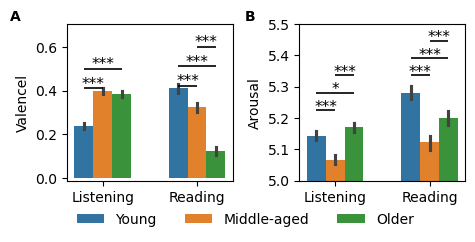

In [20]:
import itertools
import matplotlib.pyplot as plt
import seaborn as sns
fig,axes = plt.subplots(nrows=1,ncols=2,figsize=(4*1.2,1.8*1.2),sharex=True)
for ax,var,label in zip(axes.flatten(),['V','A'],['Valencel','Arousal']):
        
    sns.barplot(df_ratings,x='modality',y=var,hue='group',ax=ax,
                order = ['audio','text'],
                hue_order = ['young','middle','old'],
                width = 0.6)
    
    if var == 'V':
        min_height_gap=0.025
        text_offset=-0.03
        height_step=0.2
    else:
        min_height_gap=0.01
        text_offset=-0.0025
        height_step=0.01
    add_sig_for_seaborn(
        df = df_ratings,x='modality',y=var,hue='group',ax=ax,
        order = ['audio','text'],
        hue_order = ['young','middle','old'],
        width=0.6,
        # p_thresholds=((0.001, "***"), (0.01, "**"), (0.05, "*")),
        # test_type="paired",     # "independent" or "paired"
        # subject=['audio','subID','segID'],                # required if test_type="paired"
        # within_subject_agg="mean",   # used only for paired
        # equal_var=False,             # Welch by default for independent
        # nan_policy="omit",           # for independent only
        # alternative="two-sided",
        # --- annotation placement controls ---
        # annot_loc="auto",            # "above", "below", or "auto" (per x bin)
        text_offset=text_offset,           # fraction of y-range
        height_step=height_step,            # fraction of y-range between stacked comps
        min_height_gap=min_height_gap,         # gap above tallest bar (if placing above)
        # min_depth_gap=0.03,          # gap below lowest bar (if placing below)
    )
    if var == 'A':
        ax.set(ylim=[5,5.5])
    ax.get_legend().set_visible(False)

    ax.set(ylabel = label,xlabel='')
plt.tight_layout()


ax.set_xticks([0, 1])
ax.set_xticklabels(['Listening', 'Reading'])

handles, labels = ax.get_legend_handles_labels()
new_labels_list = ['Young','Middle-aged','Older']

fig.legend(handles, new_labels_list, title='',ncol=3,
        frameon=False, loc='center', bbox_to_anchor=(0.51, 0))
fig.text(x=0.02,y=0.92,s='A', fontweight='bold')
fig.text(x=0.51,y=0.92,s='B', fontweight='bold')

Dir_output = os.path.join(Dir_github,'derivatives','behavioral','figures&tables') 
fig.savefig(os.path.join(Dir_output,f"Fig3_barplot.jpg"),dpi=600,bbox_inches='tight')

In [131]:
audio_overall['V']['pairwise']

,comparison,t,p,p_corr,sig
0,young vs middle,-16.852392,1.116053e-63,3.348159e-63,True
1,young vs old,-14.828806,1.016566e-49,1.524848e-49,True
2,middle vs old,1.290295,1.969498e-01,1.969498e-01,False


In [43]:
audio_overall['A']['pairwise']

,comparison,t,p,p_corr,sig
0,young vs middle,7.690933,1.467417e-14,2.201125e-14,True
1,young vs old,-2.562114,1.040447e-02,1.040447e-02,True
2,middle vs old,-9.798824,1.153480e-22,3.460441e-22,True


In [42]:
text_overall['V']['pairwise']

,comparison,t,p,p_corr,sig
0,young vs middle,5.772544,7.832116e-09,7.832116e-09,True
1,young vs old,19.573735,3.791977e-85,1.137593e-84,True
2,middle vs old,13.899341,7.070388e-44,1.060558e-43,True


In [44]:
text_overall['A']['pairwise']

,comparison,t,p,p_corr,sig
0,young vs middle,10.611913,2.712768e-26,8.138303e-26,True
1,young vs old,5.382948,7.344824e-08,1.101724e-07,True
2,middle vs old,-4.965442,6.866537e-07,6.866537e-07,True


In [135]:
df = df_ratings.copy()

# Clean
df = df.dropna(subset=['V','A'])

# Extract narrative
df['narrative'] = np.where(
    df['modality'] == 'audio',
    df['audio'].str.split('_', n=1).str[1],
    df['text']
)

df_agg = (
    df.groupby(['narrative','group','modality'], observed=True)
      [['V','A']]
      .mean()
      .reset_index()
)

df_wide = df_agg.pivot(
    index=['narrative','group'],
    columns='modality',
    values=['V','A']
).reset_index()

from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

results = []

for g in ['young','middle','old']:
    d = df_wide[df_wide['group'] == g]
    
    for dv in ['V','A']:
        t, p = ttest_rel(
            d[(dv, 'audio')],
            d[(dv, 'text')],
            nan_policy='omit'
        )
        
        results.append({
            'group': g,
            'dimension': dv,
            't': t,
            'p': p
        })

df_modality_ratings = pd.DataFrame(results)

# FDR correction
df_modality_ratings['p_corr'] = multipletests(df_modality_ratings['p'], method='fdr_bh')[1]
df_modality_ratings['sig'] = df_modality_ratings['p_corr'] < 0.05

df_modality_ratings

,group,dimension,t,p,p_corr,sig
0,young,V,-4.396705,0.000252,0.000755,True
1,young,A,-1.664208,0.110923,0.166384,False
2,middle,V,1.913166,0.069459,0.138918,False
3,middle,A,-0.416711,0.681119,0.681119,False
4,old,V,6.700148,0.000001,0.000007,True
5,old,A,-0.508299,0.616542,0.681119,False


In [38]:
df_icc['group'] = pd.Categorical(
    df_icc['group'],
    categories=['young', 'middle', 'old'],
    ordered=True
)

df_icc_pivot = df_icc.pivot(
    index='audio',
    columns='group',
    values=['ICC_valence', 'ICC_arousal']
).reset_index()

df_icc_pivot[['voice', 'narrative']] = df_icc_pivot['audio'].str.split('_', n=1, expand=True)
df_icc_pivot = df_icc_pivot.sort_values('narrative').set_index(['narrative', 'voice'])[['ICC_valence','ICC_arousal']].round(2)

# summary
val_mean = df_icc_pivot['ICC_valence'].mean()
val_sd   = df_icc_pivot['ICC_valence'].std()
val_min  = df_icc_pivot['ICC_valence'].min()
val_max  = df_icc_pivot['ICC_valence'].max()

aro_mean = df_icc_pivot['ICC_arousal'].mean()
aro_sd   = df_icc_pivot['ICC_arousal'].std()
aro_min  = df_icc_pivot['ICC_arousal'].min()
aro_max  = df_icc_pivot['ICC_arousal'].max()

summary_icc = pd.DataFrame({
    'Valence': [
        f"{val_mean[g]:.2f} ± {val_sd[g]:.2f} [{val_min[g]:.2f}–{val_max[g]:.2f}]"
        for g in val_mean.index
    ],
    'Arousal': [
        f"{aro_mean[g]:.2f} ± {aro_sd[g]:.2f} [{aro_min[g]:.2f}–{aro_max[g]:.2f}]"
        for g in aro_mean.index
    ],
}, index=val_mean.index)

summary_icc.index.name = 'Age group'
summary_icc

,Valence,Arousal
Age group,,
young,0.86 ± 0.07 [0.59–0.96],0.61 ± 0.12 [0.28–0.82]
middle,0.84 ± 0.09 [0.51–0.94],0.48 ± 0.14 [0.12–0.75]
old,0.88 ± 0.08 [0.47–0.95],0.62 ± 0.14 [0.29–0.82]


In [46]:
df_long = df_icc_pivot.stack(level=0).reset_index()
df_long.columns = ['narrative', 'voice', 'dimension', 'young', 'middle', 'old']

df_long = df_long.melt(
    id_vars=['narrative', 'voice', 'dimension'],
    value_vars=['young', 'middle', 'old'],
    var_name='group',
    value_name='ICC'
)

### by age group
from itertools import combinations
from scipy.stats import ttest_rel

from statsmodels.stats.multitest import multipletests

results = []

for dim in ['ICC_valence', 'ICC_arousal']:
    d = df_long[df_long['dimension'] == dim]
    
    for g1, g2 in combinations(['young', 'middle', 'old'], 2):
        d1 = d[d['group'] == g1].sort_values('narrative')['ICC']
        d2 = d[d['group'] == g2].sort_values('narrative')['ICC']
        
        t, p = ttest_rel(d1, d2, nan_policy='omit')
        
        results.append({
            'dimension': dim,
            'comparison': f'{g1} vs {g2}',
            't': t,
            'p': p
        })

df_pairwise = pd.DataFrame(results)

# FDR correction
reject, p_corr, _, _ = multipletests(df_pairwise['p'], method='fdr_bh')
df_pairwise['p_corr'] = p_corr
df_pairwise['significant'] = reject
### valence vs arousal

results_va = []

for g in ['young', 'middle', 'old']:
    d = df_long[df_long['group'] == g]
    
    v = d[d['dimension'] == 'ICC_valence'].sort_values('narrative')['ICC']
    a = d[d['dimension'] == 'ICC_arousal'].sort_values('narrative')['ICC']
    
    t, p = ttest_rel(v, a, nan_policy='omit')
    
    results_va.append({
        'group': g,
        't': t,
        'p': p
    })

df_val_vs_arousal = pd.DataFrame(results_va)

C:\Users\XuanR\AppData\Local\Temp\ipykernel_6920\3391862439.py:1: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  df_long = df_icc_pivot.stack(level=0).reset_index()


In [49]:
df_pairwise.loc[df_pairwise['significant']==True]

,dimension,comparison,t,p,p_corr,significant
0,ICC_valence,young vs middle,2.197440,0.033178,0.049767,True
2,ICC_valence,middle vs old,-2.926742,0.005354,0.010708,True
3,ICC_arousal,young vs middle,5.553293,0.000001,0.000007,True
5,ICC_arousal,middle vs old,-5.393745,0.000002,0.000007,True


In [44]:
df_val_vs_arousal

,group,t,p
0,young,15.103997,3.084283e-19
1,middle,18.595416,9.481100e-23
2,old,12.666520,1.931459e-16


### ICC during reading

In [51]:
results = []

for (text, group), dfn in df_ratings_text.groupby(['text', 'group']):
    
    # Drop missing values
    dfn_v = dfn.dropna(subset=['V'])
    dfn_a = dfn.dropna(subset=['A'])
    
    # Need enough raters + segments
    if dfn['subID'].nunique() < 2 or dfn['segID'].nunique() < 2:
        icc_v, icc_a = np.nan, np.nan
    else:
        try:
            icc_v = compute_icc(dfn_v, 'V')
        except:
            icc_v = np.nan
            
        try:
            icc_a = compute_icc(dfn_a, 'A')
        except:
            icc_a = np.nan
    
    results.append({
        'text': text,
        'group': group,
        'ICC_valence': icc_v,
        'ICC_arousal': icc_a,
        'N_raters': dfn['subID'].nunique()
    })

df_icc = pd.DataFrame(results)

In [52]:
df_icc['group'] = pd.Categorical(
    df_icc['group'],
    categories=['young', 'middle', 'old'],
    ordered=True
)

df_icc_pivot = df_icc.pivot(
    index='text',
    columns='group',
    values=['ICC_valence', 'ICC_arousal']
).reset_index()

# df_icc_pivot[['voice', 'narrative']] = df_icc_pivot['text'].str.split('_', n=1, expand=True)
# df_icc_pivot = df_icc_pivot.sort_values('narrative').set_index(['narrative', 'voice'])[['ICC_valence','ICC_arousal']].round(2)

# summary
val_mean = df_icc_pivot['ICC_valence'].mean()
val_sd   = df_icc_pivot['ICC_valence'].std()
val_min  = df_icc_pivot['ICC_valence'].min()
val_max  = df_icc_pivot['ICC_valence'].max()

aro_mean = df_icc_pivot['ICC_arousal'].mean()
aro_sd   = df_icc_pivot['ICC_arousal'].std()
aro_min  = df_icc_pivot['ICC_arousal'].min()
aro_max  = df_icc_pivot['ICC_arousal'].max()

summary_icc = pd.DataFrame({
    'Valence': [
        f"{val_mean[g]:.2f} ± {val_sd[g]:.2f} [{val_min[g]:.2f}–{val_max[g]:.2f}]"
        for g in val_mean.index
    ],
    'Arousal': [
        f"{aro_mean[g]:.2f} ± {aro_sd[g]:.2f} [{aro_min[g]:.2f}–{aro_max[g]:.2f}]"
        for g in aro_mean.index
    ],
}, index=val_mean.index)

summary_icc.index.name = 'Age group'
summary_icc

,Valence,Arousal
Age group,,
young,0.85 ± 0.10 [0.53–0.93],0.56 ± 0.11 [0.36–0.75]
middle,0.88 ± 0.08 [0.55–0.95],0.56 ± 0.16 [0.25–0.80]
old,0.90 ± 0.05 [0.75–0.96],0.59 ± 0.17 [0.23–0.82]


In [58]:
df_long = df_icc_pivot.copy()
df_long.columns = ['text', 'dimension', 'young', 'middle', 'old']

df_long = df_long.melt(
    id_vars=['text', 'dimension'],
    value_vars=['young', 'middle', 'old'],
    var_name='group',
    value_name='ICC'
)

### by age group
from itertools import combinations
from scipy.stats import ttest_rel

from statsmodels.stats.multitest import multipletests

results = []

for dim in ['ICC_valence', 'ICC_arousal']:
    d = df_long[df_long['dimension'] == dim]
    
    for g1, g2 in combinations(['young', 'middle', 'old'], 2):
        d1 = d[d['group'] == g1].sort_values('narrative')['ICC']
        d2 = d[d['group'] == g2].sort_values('narrative')['ICC']
        
        t, p = ttest_rel(d1, d2, nan_policy='omit')
        
        results.append({
            'dimension': dim,
            'comparison': f'{g1} vs {g2}',
            't': t,
            'p': p
        })

df_pairwise = pd.DataFrame(results)

# FDR correction
reject, p_corr, _, _ = multipletests(df_pairwise['p'], method='fdr_bh')
df_pairwise['p_corr'] = p_corr
df_pairwise['significant'] = reject
### valence vs arousal

results_va = []

for g in ['young', 'middle', 'old']:
    d = df_long[df_long['group'] == g]
    
    v = d[d['dimension'] == 'ICC_valence'].sort_values('narrative')['ICC']
    a = d[d['dimension'] == 'ICC_arousal'].sort_values('narrative')['ICC']
    
    t, p = ttest_rel(v, a, nan_policy='omit')
    
    results_va.append({
        'group': g,
        't': t,
        'p': p
    })

df_val_vs_arousal = pd.DataFrame(results_va)

ValueError: Length mismatch: Expected axis has 7 elements, new values have 5 elements